# Why Britain voted Leave: statistical tests and KPIs

**Project:** Why Britain voted Leave, and where the explanation breaks

**Goal of this notebook:** the exploration notebook (01) found patterns with charts. This notebook **tests** them. For each step we explain:

1. **What the test is**, in simple words.
2. **Why we use it** for this data.
3. **What the result says**, and what it doesn't say.

**Where this notebook fits in the project**

| Notebook | What it does |
|---|---|
| 01 Data exploration | Finds the patterns with charts and maps |
| **02 Statistical tests (this one)** | Tests whether the patterns are real, how big they are, and where they stop working |
| 03 Scotland in depth | Compares Scotland's 2016 EU vote with its 2014 independence vote |
| 04 What-if scenario (optional) | Shows how a future independence vote could spread across councils, without predicting it |
| Tableau dashboards | Present the results; this notebook exports two files for them (section 13) |
| Machine learning (later) | Predicts each area's Leave share and studies where the model fails |

**Scope:** the project is about the vote across areas. The Twitter section (12) is **optional** and covers only Brexit tweets around the vote. There is no disinformation analysis.

**Roadmap**

| Step | Question | Tests used |
|---|---|---|
| 3 | What shape does each variable have? | Skewness, kurtosis, Shapiro-Wilk, Q-Q plot |
| 4 | Which characteristics move with Leave? | Pearson and Spearman correlation, confidence intervals, Benjamini-Hochberg correction |
| 5 | Do regions really differ? | Levene, Welch ANOVA, Kruskal-Wallis, effect sizes |
| 6 | KPIs: how big is each gap? | Leave share by fifth of areas (quintiles), R² of each factor alone |
| 7 | What explains Leave when we combine factors? | Weighted linear regression, robust standard errors |
| 8 | Can we trust the regression? | Residual checks, Breusch-Pagan, VIF, Cook's distance, t-tests on residuals |
| 9 | Which factors matter most? | Standardised coefficients, unique R² (drop-one test) |
| 10 | Do neighbouring areas vote alike? | Moran's I with a permutation test, residual map |
| 11 | Scotland: is Remain 2016 linked to Yes 2014? | Permutation test, bootstrap, power calculation |
| 12 | *(Optional)* Twitter: did the Brexit debate shift before the vote? | Kendall trend test, autocorrelation, chi-square, Cramér's V |
| 13 | Export results for Tableau | Model predictions and errors per area, KPI table |

## Key terms in simple words

| Term | Meaning |
|---|---|
| **Distribution** | How the values of one variable are spread out: where most areas sit, and how far the extremes go. |
| **Normal distribution** | The classic bell curve: symmetric, with most values near the middle. Many tests assume it. |
| **Skewness** | How lopsided a distribution is. 0 = symmetric. Positive = a long tail to the right (a few very high values). Negative = a long tail to the left. Between -0.5 and 0.5 is roughly symmetric. |
| **Kurtosis** | How heavy the tails are. We report *excess* kurtosis: 0 for a normal curve, above 1 means more extreme values than normal. |
| **Q-Q plot** | A chart that compares our data with a perfect bell curve. If the dots follow the straight line, the data is close to normal. |
| **Shapiro-Wilk test** | A test of "is this normal?". A p-value below 0.05 says it isn't. With many observations it flags even tiny differences, so we read it together with the Q-Q plot. |
| **Pearson r** | Correlation for a straight-line link. Sensitive to outliers. |
| **Spearman ρ (rho)** | Correlation based on ranks (1st, 2nd, 3rd…). It doesn't care about outliers or curves, only about "when one goes up, does the other go up?". |
| **Confidence interval (95% CI)** | The range where the true value probably sits. A narrow interval means a precise estimate. If it includes 0, we can't rule out "no link". |
| **Effect size** | How *big* a difference or link is, not just whether it exists. A p-value tells you "probably real"; an effect size tells you "how much". |
| **Multiple testing** | If you run 20 tests, about 1 will look significant by chance. A correction (Benjamini-Hochberg) adjusts the p-values for this. |
| **Regression** | A model that predicts Leave from several characteristics at once, so we see the effect of each one *holding the others fixed*. |
| **R²** | The share of the differences between areas that the model explains. 0.72 = 72%. |
| **Residual** | Real Leave share minus the model's prediction. Positive = the area voted more Leave than expected. |
| **Heteroscedasticity** | The model's errors are bigger for some areas than others. It makes normal standard errors wrong, so we use *robust* ones. |
| **VIF** | Variance Inflation Factor: how much a predictor repeats the others. Above 5 is a warning, above 10 a problem. |
| **Permutation test** | We shuffle the data many times to see how often chance alone produces a result as strong as ours. No bell-curve assumption needed. |
| **Bootstrap** | We resample our own data many times to see how much a result could move. Gives a confidence interval without assumptions. |
| **Moran's I** | Measures whether neighbouring areas have similar values. 0 = no pattern, close to 1 = strong clustering. |
| **KPI** | Key Performance Indicator: one headline number that summarises a finding, such as "areas with the fewest graduates voted 24 points more Leave". |

**Remember:** all results describe **areas, not individual voters**. If graduate-heavy areas voted Remain, that doesn't prove each graduate voted Remain.

## How a statistical test works, in four steps

Every test in this notebook follows the same four steps. Once you know them, every result reads the same way.

**Step 1: start from a "boring" assumption, the null hypothesis.** The test assumes there is **nothing** going on: "there is no link between graduates and Leave", "all regions voted the same", "the data is a bell curve". A test never proves the interesting idea directly. It checks whether the boring one is believable.

**Step 2: measure what we see in the data.** For example, the correlation between graduates and Leave is r = -0.77.

**Step 3: ask how surprising that would be if the boring assumption were true. That's the p-value.** A p-value of 0.03 means: *if there were really no link, chance alone would give a result this strong only about 3 times in 100.* The usual rule: **below 0.05, we reject the boring assumption** and call the result "statistically significant".

**Step 4: ask how big the effect is. That's the effect size.** A p-value only says "probably not chance". It doesn't say whether the effect is large or tiny. With 380 areas, or millions of tweets, even a tiny effect can get a small p-value. So for every test we also report an **effect size** (a correlation r, a gap in points, a share explained) and, where possible, a **95% confidence interval**: the range where the true value probably sits.

**An everyday example:** you flip a coin 10 times and get 8 heads. The boring assumption is "the coin is fair". The p-value asks how often a fair coin would give 8 or more heads out of 10 (about 5 times in 100). The effect size is how unfair the coin seems: 80% heads instead of 50%.

**Two traps to keep in mind**

- **Correlation is not causation.** Two things moving together doesn't prove one causes the other: both may come from a third cause.
- **Areas, not voters.** Every result describes areas. If graduate-heavy areas voted Remain, that doesn't prove each graduate voted Remain (this trap is called the *ecological fallacy*).

## 1. Setup

We import the libraries, use the same chart style and colours as notebook 01, and fix a **random seed**. Permutation tests and the bootstrap use random shuffles: the seed makes them give the same answer every time you run the notebook.

In [1]:
# pandas handles the tables, numpy the maths
import pandas as pd
import numpy as np

# matplotlib and seaborn draw the charts
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.collections import PolyCollection

# scipy gives us the statistical tests
from scipy import stats

# json reads the map boundaries, Path handles folders
import json
from pathlib import Path

# Same chart style as notebook 01
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# One fixed colour per group, used in every chart
SCOTLAND = "#2a78d6"
LONDON = "#eb6834"
OTHER = "#b5b3ac"

# Fixed seed: random shuffles give the same result on every run
rng = np.random.default_rng(42)

## 2. Load the data

We load the same clean tables as notebook 01, plus the **hourly** tweet file (it tells us which hours fall before the vote) and the **area boundaries** (for the map and the neighbour test).

We also add three helper columns:
- `group`: Scotland, London or Other, for colouring charts.
- `scotland` and `london`: 1 if the area is in that group, 0 if not. A regression can use these 0/1 columns, called **dummy variables**.

In [2]:
# The folder that holds the clean files (same as notebook 01)
DATA_DIR = Path("../data")  # the data folder of this repository

areas = pd.read_csv(DATA_DIR / "gb_areas_clean.csv")
scotland = pd.read_csv(DATA_DIR / "scotland_2014_2016.csv")
hourly = pd.read_csv(DATA_DIR / "tweets_hourly_stance.csv", parse_dates=["hour_utc"])
with open(DATA_DIR / "gb_areas_boundaries.geojson") as f:
    geo = json.load(f)

# Helper columns for charts and models
areas["group"] = np.select([areas["nation"] == "Scotland", areas["region"] == "London"],
                           ["Scotland", "London"], "Other")
areas["scotland"] = (areas["nation"] == "Scotland").astype(int)
areas["london"] = (areas["region"] == "London").astype(int)
COLOURS = {"Scotland": SCOTLAND, "London": LONDON, "Other": OTHER}

print("Areas:", areas.shape)
print("Scottish councils:", scotland.shape)
print("Tweet hours:", hourly.shape)
print("Map shapes:", len(geo["features"]))

Areas: (380, 29)
Scottish councils: (32, 17)
Tweet hours: (1046, 6)
Map shapes: 380


## 3. What shape does each variable have?

**Why this matters:** many tests (Pearson correlation, t-tests, classic ANOVA, regression p-values) work best when data is roughly bell-shaped. If a variable is very lopsided or has extreme values, we either use a test that doesn't need the bell shape (Spearman, Kruskal-Wallis, permutation) or transform the variable (for example, take its log).

**An important detail:** regression does **not** need each variable to be normal. It needs the model's **errors (residuals)** to be roughly normal and evenly spread. We check the variables now to spot problems early, and the residuals in step 8.

### 3.1 Shape summary for each variable

**The tests in this cell**

- **Skewness** (`stats.skew`): is the distribution lopsided?
- **Excess kurtosis** (`stats.kurtosis`): are there more extreme values than in a bell curve?
- **Shapiro-Wilk** (`stats.shapiro`): a formal test of normality. Null hypothesis: "the data is normal". A p-value below 0.05 rejects normality.

**Watch out:** with 380 areas, Shapiro-Wilk rejects normality for almost anything, even differences too small to matter. So our **verdict uses skewness first**: |skew| < 0.5 is fine for Pearson, otherwise we prefer Spearman or a transform.

In [3]:
def shape_summary(series):
    # Describe the shape of one column, ignoring missing values
    x = series.dropna()
    skew = stats.skew(x)
    kurt = stats.kurtosis(x)              # excess kurtosis: 0 for a bell curve
    shapiro_p = stats.shapiro(x).pvalue   # below 0.05 = not normal

    # Plain-language verdict based on skewness
    if abs(skew) < 0.5:
        shape = "roughly symmetric"
    elif abs(skew) < 1:
        shape = "moderately skewed " + ("right" if skew > 0 else "left")
    else:
        shape = "strongly skewed " + ("right" if skew > 0 else "left")
    if kurt > 1:
        shape += ", extreme values"

    return pd.Series({"n": len(x), "mean": x.mean(), "median": x.median(), "sd": x.std(),
                      "skew": skew, "excess_kurtosis": kurt, "shapiro_p": shapiro_p,
                      "shape": shape,
                      "use": "Pearson OK" if abs(skew) < 0.5 else "Spearman / transform"})


VARIABLES = ["leave_pct", "turnout_pct", "pct_degree", "pct_noqual", "pct_ab", "pct_de",
             "pct_65plus", "pct_18_29", "median_weekly_pay", "claimant_rate",
             "child_poverty_pct", "ukip_2014_pct", "pct_nonuk_born"]

shapes = areas[VARIABLES].apply(shape_summary).T
display(shapes.round(3))

,n,mean,median,sd,skew,excess_kurtosis,shapiro_p,shape,use
leave_pct,380,53.14072,54.29775,10.415762,-0.670303,0.347701,0.0,moderately skewed left,Spearman / transform
turnout_pct,380,73.757704,74.3486,5.055718,-0.504319,-0.259196,0.000003,moderately skewed left,Spearman / transform
pct_degree,380,26.922654,25.7614,7.669481,1.215323,2.728908,0.0,"strongly skewed right, extreme values",Spearman / transform
pct_noqual,380,22.824648,22.6455,5.145208,0.082711,-0.295577,0.348797,roughly symmetric,Pearson OK
pct_ab,380,22.638508,21.11725,7.824725,0.991081,1.304636,0.0,"moderately skewed right, extreme values",Spearman / transform
pct_de,380,24.821819,24.2507,6.844022,0.136001,-0.559301,0.026939,roughly symmetric,Pearson OK
pct_65plus,380,17.551799,17.3124,3.899771,0.063297,0.589721,0.018596,roughly symmetric,Pearson OK
pct_18_29,380,15.016047,13.86265,4.035338,1.501412,2.210533,0.0,"strongly skewed right, extreme values",Spearman / transform
median_weekly_pay,379,531.574406,518.0,71.907192,1.003581,1.337719,0.0,"strongly skewed right, extreme values",Spearman / transform
claimant_rate,380,1.569474,1.4,0.870274,0.952423,0.600728,0.0,moderately skewed right,Spearman / transform


**How to read the table**

- `mean` vs `median`: if the mean is clearly above the median, a few high values pull it up (right skew).
- `skew` is the main number to read. `shapiro_p` below 0.05 just confirms that the data isn't a perfect bell curve.

**What we see**

- **Leave share** is **moderately skewed to the left** (skew -0.67): most areas are between 45% and 65%, with a tail of strong Remain areas (London, Scotland, university cities). This is close enough to a bell shape for regression.
- **Roughly symmetric:** no qualifications, social grade DE, the 65+ share and EP 2014 turnout.
- **Skewed to the right:** graduate share (1.2), the 18-29 share (1.5), median pay (1.0) and non-UK-born share (2.0). A few areas (London boroughs, university towns) have very high values.
- `pct_nonuk_born` has only 340 values (no Scotland), which is one more reason it stays out of the Great Britain model.

### 3.2 Histograms and Q-Q plots

Numbers are easier to trust when we can see them. For six key variables we draw:

- a **histogram** (how many areas fall in each band), with the **mean** (solid line) and **median** (dashed line);
- a **Q-Q plot** for Leave share and graduate share. If the dots follow the red line, the data is close to normal. Dots that curve away at the ends show skew or extreme values.

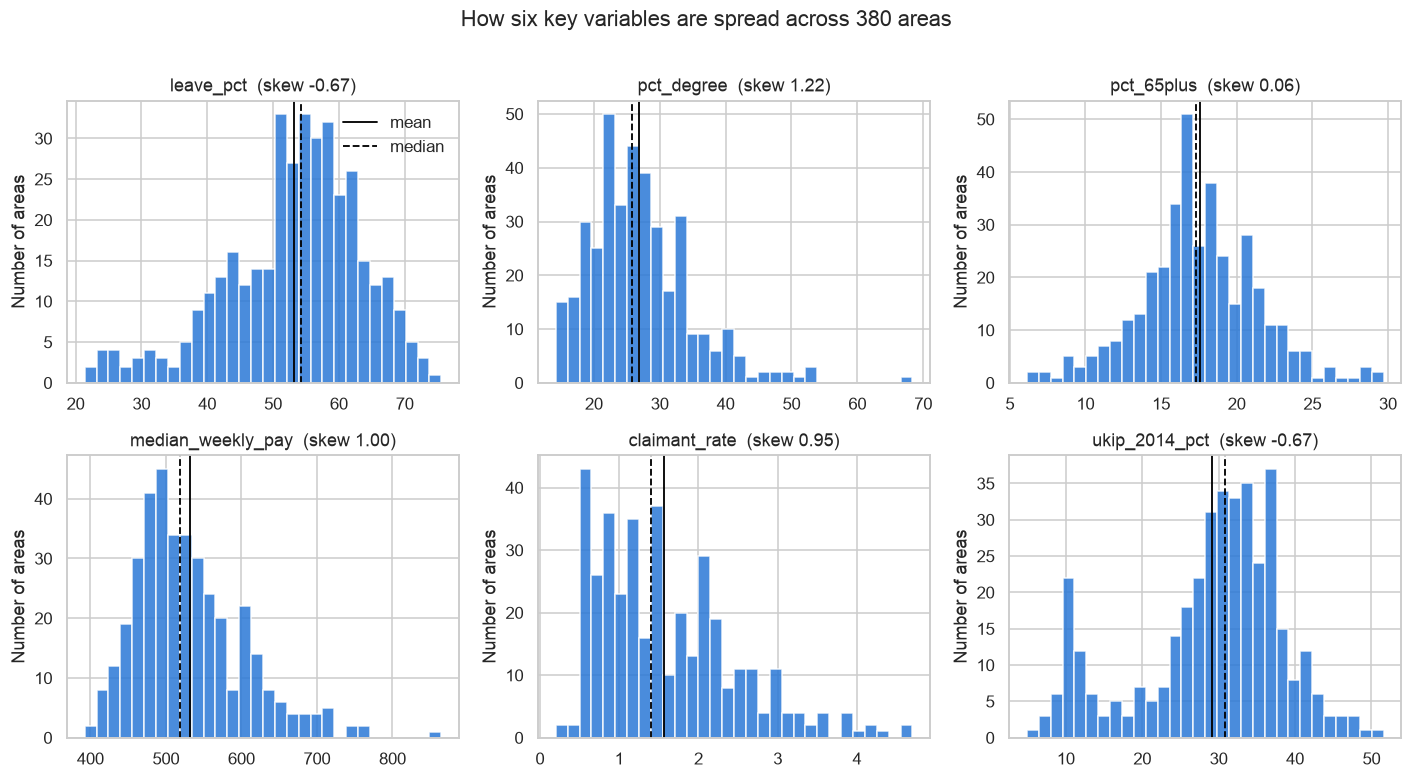

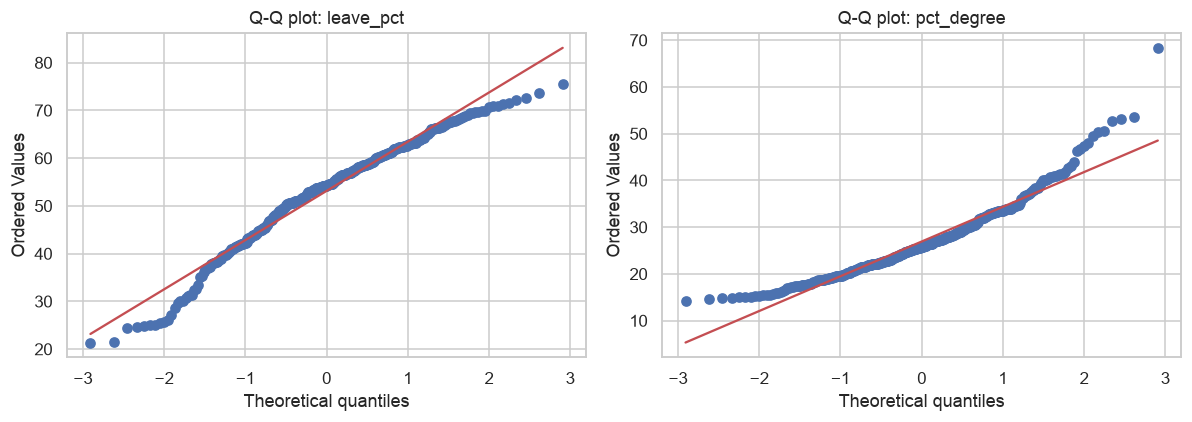

In [4]:
KEY = ["leave_pct", "pct_degree", "pct_65plus", "median_weekly_pay", "claimant_rate", "ukip_2014_pct"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, column in zip(axes.ravel(), KEY):
    x = areas[column].dropna()
    ax.hist(x, bins=30, color=SCOTLAND, edgecolor="white", alpha=0.85)
    ax.axvline(x.mean(), color="black", linewidth=1.2, label="mean")
    ax.axvline(x.median(), color="black", linewidth=1.2, linestyle="--", label="median")
    ax.set_title(f"{column}  (skew {stats.skew(x):.2f})")
    ax.set_ylabel("Number of areas")
axes[0, 0].legend(frameon=False)
fig.suptitle("How six key variables are spread across 380 areas", y=1.01)
fig.tight_layout()
plt.show()

# Q-Q plots: do the dots follow a bell-curve line?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ["leave_pct", "pct_degree"]):
    stats.probplot(areas[column].dropna(), dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {column}")
fig.tight_layout()
plt.show()

**What we see**

- **Leave share:** the dots follow the line in the middle and drop below it on the left. That's the tail of strong Remain areas. The middle 90% of areas look close to normal.
- **Graduate share:** the dots bend upwards on the right. A small group of areas (central London, Cambridge, Oxford) has far more graduates than a bell curve would predict.
- **Claimant rate:** most areas sit between 0.5% and 2.5%, with a long right tail of areas with higher claimant rates.

### 3.3 Does a log transform fix the skew?

Taking the **logarithm** shrinks large values more than small ones, so it pulls in a long right tail. We test it on the three most right-skewed variables. If the skew moves close to 0, the log version suits linear methods better.

In [5]:
for column in ["pct_degree", "pct_18_29", "claimant_rate", "pct_nonuk_born", "median_weekly_pay"]:
    x = areas[column].dropna()
    print(f"{column:18s} skew before {stats.skew(x):5.2f}   after log {stats.skew(np.log(x)):5.2f}")

pct_degree         skew before  1.22   after log  0.27
pct_18_29          skew before  1.50   after log  0.90
claimant_rate      skew before  0.95   after log -0.15
pct_nonuk_born     skew before  2.05   after log  0.22
median_weekly_pay  skew before  1.00   after log  0.60


**What we see:** the log brings the graduate share, claimant rate and non-UK-born share close to symmetric. The 18-29 share stays skewed, because its tail comes from a few student towns rather than a smooth spread.

**Decision:** we keep the original percentages in the main model, because "1 point more graduates" is easy to explain. We use **robust standard errors** and **Spearman** to protect against the skew, and keep the log versions as a robustness check.

## 4. Which characteristics move with the Leave vote?

**The tests**

- **Pearson r** measures the straight-line link. `stats.pearsonr` also gives a **95% confidence interval**.
- **Spearman ρ** measures the rank link. It's robust to outliers and skew.
- **Comparing them:** if Pearson and Spearman are close, the link is real across all areas. If they differ a lot, a few extreme areas are driving the Pearson value.
- **Benjamini-Hochberg correction** (`stats.false_discovery_control`): we test 12 variables at once, so a few could look significant by luck. This correction adjusts the p-values for that.

In [6]:
PREDICTORS = ["pct_degree", "pct_noqual", "pct_ab", "pct_de", "pct_65plus", "pct_18_29",
              "median_weekly_pay", "claimant_rate", "child_poverty_pct", "ukip_2014_pct",
              "turnout_pct", "ep_2014_turnout_pct"]

rows = []
for column in PREDICTORS:
    pair = areas[["leave_pct", column]].dropna()
    pearson = stats.pearsonr(pair["leave_pct"], pair[column])
    ci = pearson.confidence_interval(confidence_level=0.95)
    spearman = stats.spearmanr(pair["leave_pct"], pair[column])
    rows.append({"variable": column, "n": len(pair),
                 "pearson_r": pearson.statistic, "ci_low": ci.low, "ci_high": ci.high,
                 "spearman_rho": spearman.statistic, "p_value": pearson.pvalue})

correlations = pd.DataFrame(rows)
# Adjust the p-values for running 12 tests at once
correlations["p_adjusted"] = stats.false_discovery_control(correlations["p_value"])
correlations["gap"] = correlations["spearman_rho"] - correlations["pearson_r"]
correlations = correlations.sort_values("pearson_r").reset_index(drop=True)
display(correlations.round(3))

,variable,n,pearson_r,ci_low,ci_high,spearman_rho,p_value,p_adjusted,gap
0,pct_degree,380,-0.773,-0.810,-0.729,-0.752,0.000,0.000,0.021
1,pct_ab,380,-0.581,-0.644,-0.510,-0.561,0.000,0.000,0.020
2,median_weekly_pay,379,-0.503,-0.575,-0.424,-0.471,0.000,0.000,0.032
3,ep_2014_turnout_pct,380,-0.394,-0.475,-0.305,-0.370,0.000,0.000,0.023
4,pct_18_29,380,-0.374,-0.457,-0.284,-0.115,0.000,0.000,0.258
5,child_poverty_pct,379,0.073,-0.028,0.173,0.222,0.154,0.154,0.149
6,turnout_pct,380,0.109,0.008,0.207,0.002,0.034,0.037,-0.106
7,claimant_rate,380,0.117,0.017,0.215,0.181,0.022,0.026,0.063
8,pct_65plus,380,0.366,0.275,0.450,0.252,0.000,0.000,-0.114
9,pct_de,380,0.408,0.320,0.488,0.432,0.000,0.000,0.024


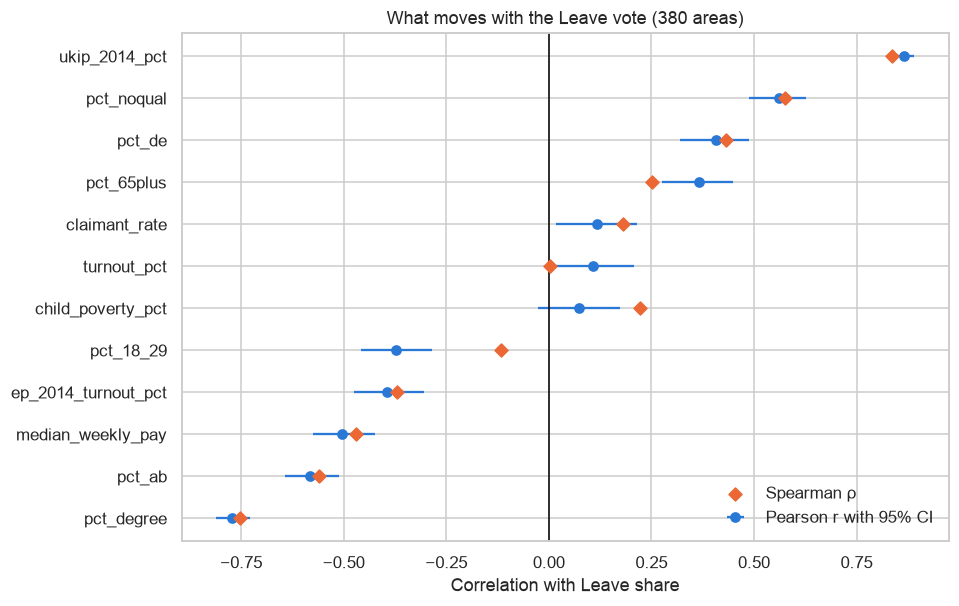

In [7]:
# Chart: Pearson (dot + confidence interval) next to Spearman (diamond)
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(correlations))
ax.errorbar(correlations["pearson_r"], y,
            xerr=[correlations["pearson_r"] - correlations["ci_low"],
                  correlations["ci_high"] - correlations["pearson_r"]],
            fmt="o", color=SCOTLAND, label="Pearson r with 95% CI")
ax.scatter(correlations["spearman_rho"], y, marker="D", color=LONDON, label="Spearman ρ", zorder=3)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y, correlations["variable"])
ax.set_xlabel("Correlation with Leave share")
ax.set_title("What moves with the Leave vote (380 areas)")
ax.legend(frameon=False, loc="lower right")
plt.show()

**What we see**

- **UKIP 2014 share (r = 0.87)** and **graduate share (r = -0.77, 95% CI -0.81 to -0.73)** have the strongest links. Pearson and Spearman agree, so the links hold across all areas, not just a few extreme ones.
- **No qualifications (+0.56)**, **social grade AB (-0.58)** and **median pay (-0.50)** follow the same education and class pattern.
- **The 18-29 share:** Pearson says -0.37 but Spearman only -0.12. A few student towns and London boroughs with very young populations create most of the Pearson value. **We shouldn't present "young areas voted Remain" as a strong finding.**
- **The 65+ share:** Pearson 0.37 but Spearman 0.25, so the link is moderate.
- **Claimant rate (0.12)** and **child poverty (0.07)** barely move with Leave across Great Britain. Child poverty is the only variable that **stops being significant** after the correction (adjusted p = 0.15).

**Reminder:** correlation isn't causation. UKIP 2014 is a strong link because it measures the same political mood two years earlier, not because it explains *why* people held that view.

## 5. Do regions really differ?

Notebook 01 showed different Leave levels by region. Now we test whether these differences are bigger than chance.

**The tests, in order**

1. **Levene's test:** do the regions have the **same spread** (variance)? Classic ANOVA assumes they do. Null hypothesis: "equal spread". A p-value below 0.05 means the spreads differ.
2. **Welch ANOVA:** compares the regional **averages** without assuming equal spread. That's why we use it instead of classic ANOVA. Null hypothesis: "all regions have the same average Leave share".
3. **Kruskal-Wallis:** the rank-based version of ANOVA. It compares **medians** and doesn't need normal data. If both tests agree, the result is solid.
4. **Effect sizes:**
   - **η² (eta squared)**: the share of the differences between areas explained by region alone.
   - **ε² (epsilon squared)**: the same idea for Kruskal-Wallis.
   - Rough guide: 0.01 small, 0.06 medium, 0.14 large.

In [8]:
# One array of Leave shares per region
groups = [g["leave_pct"].to_numpy() for _, g in areas.groupby("region")]
k, n = len(groups), len(areas)

levene = stats.levene(*groups)
welch = stats.f_oneway(*groups, equal_var=False)   # Welch ANOVA
kruskal = stats.kruskal(*groups)

# Effect sizes
grand_mean = areas["leave_pct"].mean()
between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
total = ((areas["leave_pct"] - grand_mean) ** 2).sum()
eta2 = between / total
eps2 = (kruskal.statistic - k + 1) / (n - k)

print(f"Levene (equal spread?):  W = {levene.statistic:.2f}, p = {levene.pvalue:.1e}")
print(f"Welch ANOVA:             F = {welch.statistic:.1f}, p = {welch.pvalue:.1e}, eta² = {eta2:.2f}")
print(f"Kruskal-Wallis:          H = {kruskal.statistic:.1f}, p = {kruskal.pvalue:.1e}, epsilon² = {eps2:.2f}")

summary = (areas.groupby("region")["leave_pct"]
           .agg(areas="count", median="median", sd="std", min="min", max="max")
           .sort_values("median").round(1))
display(summary)

Levene (equal spread?):  W = 4.44, p = 6.5e-06
Welch ANOVA:             F = 32.5, p = 2.8e-29, eta² = 0.44
Kruskal-Wallis:          H = 144.2, p = 5.9e-26, epsilon² = 0.36


,areas,median,sd,min,max
region,,,,,
London,33,38.4,12.8,21.4,69.7
Scotland,32,39.8,5.7,25.6,49.9
South East,67,51.9,7.7,29.7,65.4
Wales,22,54.0,5.5,40.0,62.0
South West,37,54.1,6.1,38.3,63.2
East,47,56.5,9.6,26.2,72.7
Yorkshire and The Humber,21,56.8,7.9,42.0,69.9
North West,39,56.8,6.8,39.6,67.5
North East,12,59.4,5.9,49.3,69.6


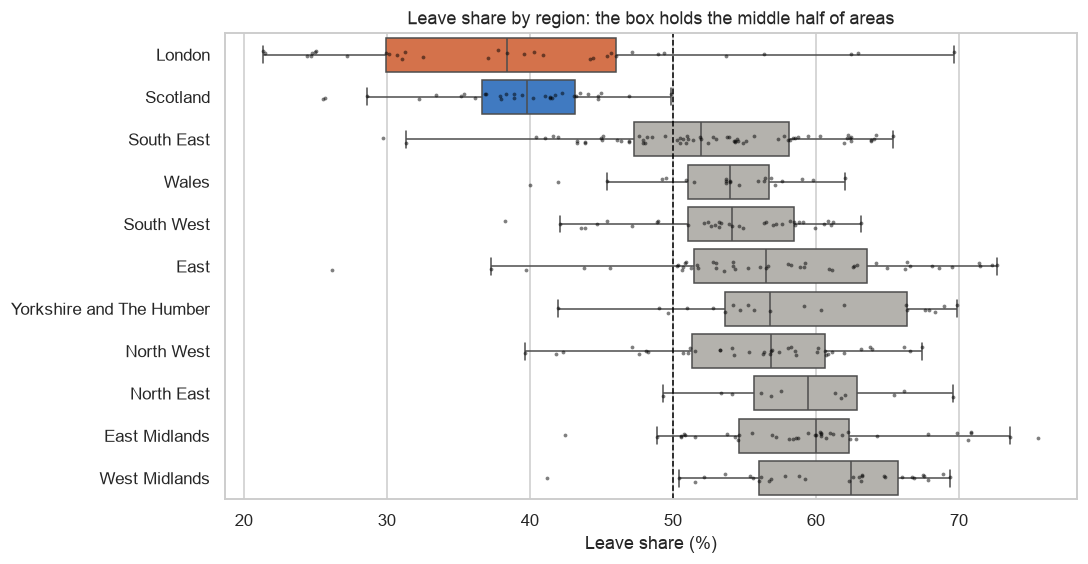

In [9]:
# Box plot, regions sorted by median Leave share
order = summary.index.tolist()
palette = {r: (SCOTLAND if r == "Scotland" else LONDON if r == "London" else OTHER) for r in order}
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=areas, y="region", x="leave_pct", order=order, hue="region", palette=palette,
            legend=False, ax=ax, fliersize=0)
sns.stripplot(data=areas, y="region", x="leave_pct", order=order, color="black", size=2.5, alpha=0.5, ax=ax)
ax.axvline(50, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Leave share (%)")
ax.set_ylabel("")
ax.set_title("Leave share by region: the box holds the middle half of areas")
plt.show()

**What we see**

- **Levene p < 0.001:** the regions don't have the same spread. London's standard deviation is 12.8 points, against about 6 in most regions. So classic ANOVA would be wrong, and **Welch ANOVA** is the right choice.
- **Welch ANOVA** (F = 32.5) and **Kruskal-Wallis** (H = 144) both give p < 0.001. Regions really differ.
- **The effect is large:** η² = 0.44. Region alone explains about 44% of the differences between areas.
- London (median 38.4%) and Scotland (39.8%) are at the bottom, and the West Midlands (62.4%) and East Midlands (60.0%) at the top.

**But region is a label, not an explanation.** The next steps ask *what about* these regions explains the gap: education, age, income, or something else.

## 6. KPIs: how big are the gaps?

Correlations are hard to explain to a non-technical audience. **KPIs** turn them into simple, concrete numbers.

**KPI 1 — Headline numbers:** the overall result and how many areas voted Leave.

**KPI 2 — The quintile gap.** For each characteristic:
1. We sort the 380 areas and cut them into **five equal groups (quintiles)**: Q1 = the fifth of areas with the lowest value, Q5 = the highest.
2. We compute the **Leave share of all votes cast in each group**. That's vote-weighted, so big cities count more than small districts.
3. **KPI = Leave share in Q5 minus Leave share in Q1.** Example: "the fifth of areas with the most graduates voted 24 points less Leave than the fifth with the fewest".

**KPI 3 — Explained alone (R²):** r², the share of the differences between areas that a characteristic explains on its own.

In [10]:
# KPI 1: headline numbers (Great Britain only: Northern Ireland and Gibraltar are not in this table)
gb_leave = 100 * areas["leave_votes"].sum() / areas["valid_votes"].sum()
leave_areas = (areas["leave_pct"] > 50).sum()
turnout_by_side = areas.groupby(areas["leave_pct"] > 50).apply(
    lambda g: 100 * g["votes_cast"].sum() / g["electorate"].sum())

print(f"Leave share, Great Britain:          {gb_leave:.1f}%")
print(f"Areas with a Leave majority:         {leave_areas} of {len(areas)} ({100 * leave_areas / len(areas):.0f}%)")
print(f"Scottish councils with a Leave majority: {(areas.query('scotland == 1')['leave_pct'] > 50).sum()} of 32")
print(f"Turnout in Leave-majority areas:     {turnout_by_side[True]:.1f}%")
print(f"Turnout in Remain-majority areas:    {turnout_by_side[False]:.1f}%")

Leave share, Great Britain:          52.1%
Areas with a Leave majority:         263 of 380 (69%)
Scottish councils with a Leave majority: 0 of 32
Turnout in Leave-majority areas:     73.2%
Turnout in Remain-majority areas:    71.1%


In [11]:
# KPI 2 and 3: quintile gaps and R² of each characteristic alone
KPI_VARS = {"pct_degree": "Graduate share", "pct_ab": "Social grade AB", "pct_noqual": "No qualifications",
            "pct_de": "Social grade DE", "pct_65plus": "Aged 65+", "pct_18_29": "Aged 18-29",
            "median_weekly_pay": "Median weekly pay", "claimant_rate": "Claimant rate",
            "child_poverty_pct": "Child poverty", "ukip_2014_pct": "UKIP vote 2014"}

quintile_rows, kpi_rows = {}, []
for column, label in KPI_VARS.items():
    data = areas[[column, "leave_votes", "valid_votes", "leave_pct"]].dropna().copy()
    data["quintile"] = pd.qcut(data[column], 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"])
    share = data.groupby("quintile", observed=True).apply(
        lambda g: 100 * g["leave_votes"].sum() / g["valid_votes"].sum())
    quintile_rows[label] = share
    r = stats.pearsonr(data[column], data["leave_pct"]).statistic
    kpi_rows.append({"characteristic": label, "Q1_leave": share.iloc[0], "Q5_leave": share.iloc[-1],
                     "gap_Q5_minus_Q1": share.iloc[-1] - share.iloc[0], "r2_alone": r ** 2})

quintiles = pd.DataFrame(quintile_rows).T.round(1)
kpis = pd.DataFrame(kpi_rows).sort_values("gap_Q5_minus_Q1").reset_index(drop=True)
display(quintiles)
display(kpis.round(2))

quintile,Q1 lowest,Q2,Q3,Q4,Q5 highest
Graduate share,63.3,55.2,53.2,50.4,39.2
Social grade AB,60.4,54.7,54.3,49.4,42.0
No qualifications,41.1,50.0,54.7,57.3,57.7
Social grade DE,46.5,49.6,52.5,53.4,57.1
Aged 65+,44.6,54.1,55.1,53.8,56.9
Aged 18-29,53.8,53.1,55.3,57.3,44.1
Median weekly pay,59.8,55.3,50.9,50.1,44.7
Claimant rate,50.7,53.1,51.4,53.5,51.9
Child poverty,48.5,52.8,52.4,55.3,50.7
UKIP vote 2014,38.2,50.8,55.1,59.1,62.7


,characteristic,Q1_leave,Q5_leave,gap_Q5_minus_Q1,r2_alone
0,Graduate share,63.30,39.17,-24.13,0.60
1,Social grade AB,60.43,41.97,-18.45,0.34
2,Median weekly pay,59.77,44.72,-15.05,0.25
3,Aged 18-29,53.75,44.12,-9.63,0.14
4,Claimant rate,50.70,51.94,1.24,0.01
5,Child poverty,48.47,50.67,2.20,0.01
6,Social grade DE,46.54,57.15,10.60,0.17
7,Aged 65+,44.60,56.90,12.29,0.13
8,No qualifications,41.12,57.67,16.55,0.31
9,UKIP vote 2014,38.22,62.69,24.47,0.75


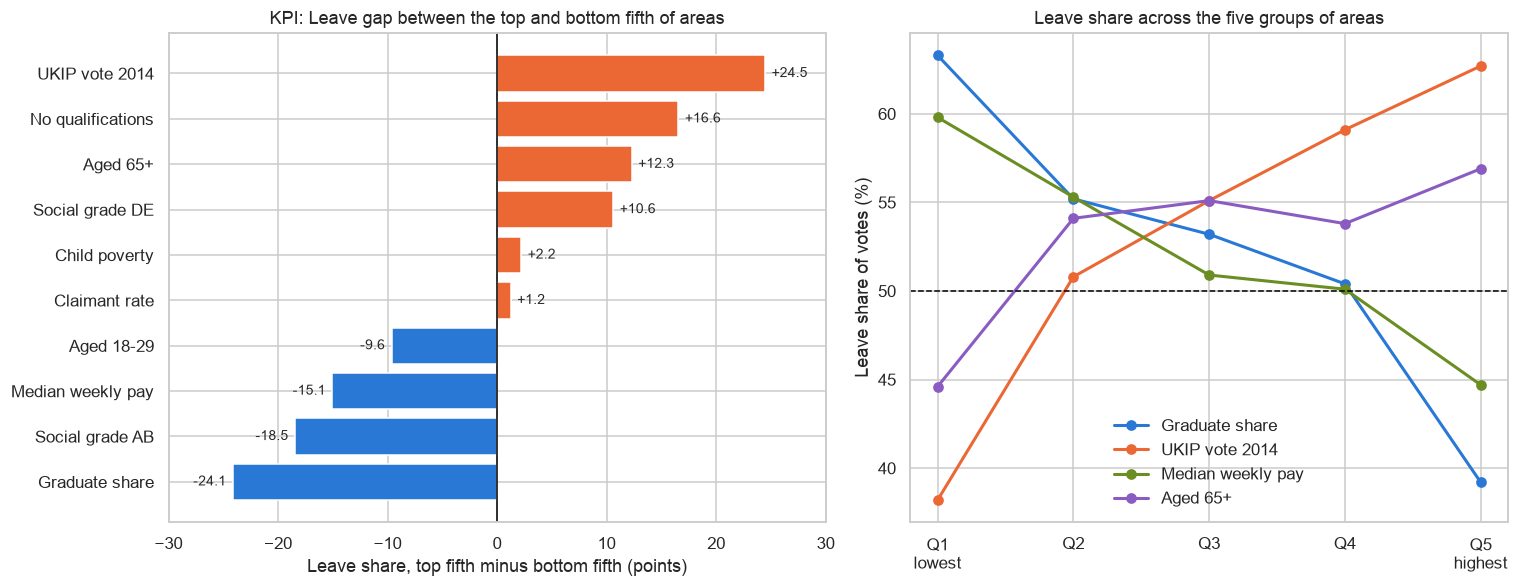

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})

# Left: the gap between the top and bottom fifth of areas
colours = [LONDON if g > 0 else SCOTLAND for g in kpis["gap_Q5_minus_Q1"]]
axes[0].barh(kpis["characteristic"], kpis["gap_Q5_minus_Q1"], color=colours)
axes[0].axvline(0, color="black", linewidth=1)
for i, g in enumerate(kpis["gap_Q5_minus_Q1"]):
    axes[0].text(g + (0.6 if g > 0 else -0.6), i, f"{g:+.1f}", va="center", ha="left" if g > 0 else "right", fontsize=9)
axes[0].set_xlabel("Leave share, top fifth minus bottom fifth (points)")
axes[0].set_title("KPI: Leave gap between the top and bottom fifth of areas")
axes[0].set_xlim(-30, 30)

# Right: the full pattern across the five groups, for four key characteristics
for label, colour in [("Graduate share", SCOTLAND), ("UKIP vote 2014", LONDON),
                      ("Median weekly pay", "#6b8e23"), ("Aged 65+", "#8a5cc2")]:
    axes[1].plot(range(1, 6), quintiles.loc[label], marker="o", label=label, color=colour, linewidth=2)
axes[1].axhline(50, color="black", linestyle="--", linewidth=1)
axes[1].set_xticks(range(1, 6), ["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"])
axes[1].set_ylabel("Leave share of votes (%)")
axes[1].set_title("Leave share across the five groups of areas")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

**The KPIs that explain the Leave vote**

| KPI | Value | In simple words |
|---|---|---|
| Leave share, Great Britain | **52.1%** | (51.9% for the whole UK, with Northern Ireland and Gibraltar) |
| Areas with a Leave majority | **263 of 380 (69%)** | Leave won most areas, often narrowly. No Scottish council voted Leave. |
| **Graduate gap** | **-24.1 points** | Fewest graduates: 63.3% Leave. Most graduates: 39.2%. Alone it explains **60%** of the differences between areas. |
| **UKIP 2014 gap** | **+24.5 points** | Areas with the most UKIP votes in 2014 voted 62.7% Leave. It explains 75% alone, but it's a political measure, not a cause. |
| **Social grade AB gap** | **-18.5 points** | The most professional and managerial areas voted 42.0% Leave, against 60.4% in the least. |
| **No qualifications gap** | **+16.6 points** | Most of the rise happens between Q1 and Q3. |
| **Pay gap** | **-15.1 points** | The lowest-paid fifth voted 59.8% Leave, the highest-paid fifth 44.7%. |
| **Age 65+ gap** | **+12.3 points** | The jump is mainly from Q1 to Q2. The youngest fifth of areas (cities) is the outlier. |
| **Age 18-29** | **-9.6 points, not steady** | Q1 to Q4 are flat (53-57%). Only the youngest fifth (cities and student towns) drops to 44%. |
| **Claimant rate** | **+1.2 points** | Almost no gap: unemployment didn't predict Leave across Great Britain. |
| **Child poverty** | **+2.2 points** | Almost no gap. |

**Main message:** the clearest demographic KPI is **education**. Income and social grade tell a similar story, because they overlap with education. **Unemployment and poverty show almost no gap**, which goes against the simple "left-behind = poor" story. Turnout was slightly higher in Leave-majority areas (73.2% vs 71.1%).

## 7. What explains Leave when we combine factors? (regression)

Each KPI looks at one characteristic alone. But graduates, pay and age are linked to each other. **Multiple regression** estimates the effect of each characteristic **holding the others fixed**.

**Choices we make, and why**

- **Predictors:** graduate share (education), 65+ and 18-29 shares (age), claimant rate (economy). We keep only **one** education measure, because notebook 01 showed that education and social grade repeat each other (we test this with VIF in step 8).
- **Weighted by valid votes:** an area with 300,000 voters counts more than one with 4,000. The results then describe *voters' areas*, not just areas.
- **Robust (HC3) standard errors:** they stay correct even if the errors are bigger in some areas (heteroscedasticity, tested in step 8).
- **Three models:**
  - **A: demographics only.** What does the social profile explain?
  - **B: A + UKIP 2014.** How much does earlier political mood add?
  - **C: A + a Scotland dummy + a London dummy.** Does a "Scotland effect" remain once we know the demographics?

### 7.1 The regression helper

This function does the maths. You don't need to follow every line: it returns the coefficients, robust standard errors, residuals and R².

In [13]:
def fit_ols(data, y, X, weight="valid_votes"):
    # Weighted least squares with HC3 robust standard errors
    d = data[[y, weight] + X].dropna()
    Xm = np.column_stack([np.ones(len(d)), d[X].to_numpy()])        # add a constant
    w = (d[weight] / d[weight].mean()).to_numpy()
    sw = np.sqrt(w)
    Xw, yw = Xm * sw[:, None], d[y].to_numpy() * sw

    beta = np.linalg.lstsq(Xw, yw, rcond=None)[0]                    # coefficients
    fitted = Xm @ beta
    resid = d[y].to_numpy() - fitted

    # HC3 robust standard errors
    XtX_inv = np.linalg.inv(Xw.T @ Xw)
    leverage = np.einsum("ij,jk,ik->i", Xw, XtX_inv, Xw)
    meat = (Xw * ((resid * sw) / (1 - leverage))[:, None] ** 2).T @ Xw
    se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))

    y_bar = np.average(d[y], weights=w)
    r2 = 1 - np.sum(w * resid ** 2) / np.sum(w * (d[y] - y_bar) ** 2)
    t = beta / se
    table = pd.DataFrame({"coef": beta, "robust_se": se, "t": t,
                          "p": 2 * stats.t.sf(np.abs(t), len(d) - len(beta)),
                          "ci_low": beta - 1.96 * se, "ci_high": beta + 1.96 * se},
                         index=["constant"] + X)
    return {"table": table, "resid": pd.Series(resid, index=d.index), "fitted": pd.Series(fitted, index=d.index),
            "r2": r2, "rmse": np.sqrt(np.mean(resid ** 2)), "leverage": leverage, "X": d[X], "n": len(d)}

### 7.2 Fit the three models

**How to read a coefficient:** "holding the other variables fixed, one more percentage point of graduates goes with **coef** points of Leave". The **95% CI** gives its likely range, and **p** says whether it could be zero.

In [14]:
DEMOGRAPHICS = ["pct_degree", "pct_65plus", "pct_18_29", "claimant_rate"]
MODELS = {"A: demographics": DEMOGRAPHICS,
          "B: demographics + UKIP 2014": DEMOGRAPHICS + ["ukip_2014_pct"],
          "C: demographics + Scotland + London": DEMOGRAPHICS + ["scotland", "london"]}

results = {}
for name, X in MODELS.items():
    results[name] = fit_ols(areas, "leave_pct", X)
    print(f"\n{name}:  n = {results[name]['n']},  weighted R² = {results[name]['r2']:.3f},  "
          f"RMSE = {results[name]['rmse']:.2f} points")
    display(results[name]["table"].round(3))


A: demographics:  n = 380,  weighted R² = 0.717,  RMSE = 5.95 points


,coef,robust_se,t,p,ci_low,ci_high
constant,97.135,4.640,20.934,0.000,88.040,106.229
pct_degree,-1.220,0.059,-20.579,0.000,-1.336,-1.104
pct_65plus,-0.048,0.118,-0.408,0.684,-0.279,0.183
pct_18_29,-0.382,0.115,-3.328,0.001,-0.607,-0.157
claimant_rate,-2.973,0.548,-5.428,0.000,-4.047,-1.900



B: demographics + UKIP 2014:  n = 380,  weighted R² = 0.914,  RMSE = 3.11 points


,coef,robust_se,t,p,ci_low,ci_high
constant,58.656,3.691,15.890,0.000,51.421,65.891
pct_degree,-0.638,0.048,-13.319,0.000,-0.732,-0.544
pct_65plus,-0.333,0.071,-4.668,0.000,-0.472,-0.193
pct_18_29,-0.280,0.068,-4.109,0.000,-0.414,-0.147
claimant_rate,0.133,0.329,0.405,0.686,-0.512,0.778
ukip_2014_pct,0.730,0.040,18.135,0.000,0.651,0.809



C: demographics + Scotland + London:  n = 380,  weighted R² = 0.876,  RMSE = 3.85 points


,coef,robust_se,t,p,ci_low,ci_high
constant,94.520,3.332,28.364,0.000,87.988,101.051
pct_degree,-1.190,0.051,-23.549,0.000,-1.289,-1.091
pct_65plus,0.066,0.083,0.793,0.428,-0.097,0.228
pct_18_29,-0.427,0.093,-4.573,0.000,-0.610,-0.244
claimant_rate,-1.978,0.396,-4.998,0.000,-2.754,-1.202
scotland,-15.454,1.396,-11.067,0.000,-18.191,-12.717
london,1.223,0.971,1.260,0.209,-0.680,3.126


**What we see**

**Model A, demographics (R² = 0.72, typical error about 6 points)**
- **Graduate share** is by far the strongest: **-1.22 points of Leave per extra point of graduates** (95% CI about -1.34 to -1.10).
- **18-29 share:** -0.38, a small but real effect.
- **The 65+ share is no longer significant** (p = 0.68). Older areas also have fewer graduates, so once education is in the model, age adds little.
- **Claimant rate becomes negative** (-2.97). On its own it barely moved with Leave, but among areas with the *same* graduate share, the ones with more claimants voted slightly *less* Leave. Many of them are in Scotland and in big cities. This sign change is a warning that the model mixes up places, which step 8 confirms.

**Model B, + UKIP 2014 (R² = 0.91, typical error about 3 points)**
- UKIP 2014 adds a lot (+0.73 Leave per UKIP point), and graduate share stays strong (-0.64).
- But UKIP 2014 measures the same Eurosceptic mood, measured two years earlier. It **predicts** Leave well, but it doesn't **explain** it.

**Model C, + Scotland and London dummies (R² = 0.88)**
- **Scotland: -15.5 points.** Even with the same graduate share, age and claimant rate, Scottish councils voted about 15 points less Leave. **Demographics can't explain Scotland.** That's the core of the "where the explanation breaks" story, explored in notebook 03.
- **London: +1.2 points, not significant.** Once graduates and age are in the model, London isn't special: its Remain vote is mostly explained by its demographics.

## 8. Can we trust the regression? (diagnostics)

A regression is only reliable if its assumptions hold. We check four things.

| Check | Test | What we want |
|---|---|---|
| Are the errors roughly normal? | Shapiro-Wilk on residuals, skewness, Q-Q plot | Skew near 0, dots on the line |
| Is the error spread even? | **Breusch-Pagan** test | p > 0.05. If not, robust standard errors (which we already use) |
| Do predictors repeat each other? | **VIF** | Below 5 |
| Do a few areas drive the result? | **Cook's distance** | No area far above 4/n |

### 8.1 Residuals: normal and evenly spread?

**Breusch-Pagan, in simple words:** we try to predict the *size* of each error from the predictors. If we can, the errors are bigger for some kinds of area than others, which is called heteroscedasticity. Null hypothesis: "the error spread is the same everywhere".

In [15]:
def breusch_pagan(resid, X):
    # Regress squared residuals on the predictors; LM = n * R² follows a chi-square
    Xm = np.column_stack([np.ones(len(X)), X])
    u = resid ** 2
    fitted = Xm @ np.linalg.lstsq(Xm, u, rcond=None)[0]
    r2 = 1 - np.sum((u - fitted) ** 2) / np.sum((u - u.mean()) ** 2)
    lm = len(u) * r2
    return lm, stats.chi2.sf(lm, X.shape[1])


diag_rows = []
for name, res in results.items():
    e = res["resid"].to_numpy()
    lm, p_bp = breusch_pagan(e, res["X"].to_numpy())
    diag_rows.append({"model": name, "residual_skew": stats.skew(e), "residual_excess_kurtosis": stats.kurtosis(e),
                      "shapiro_p": stats.shapiro(e).pvalue, "breusch_pagan_LM": lm, "breusch_pagan_p": p_bp})
display(pd.DataFrame(diag_rows).round(4))

,model,residual_skew,residual_excess_kurtosis,shapiro_p,breusch_pagan_LM,breusch_pagan_p
0,A: demographics,-1.3737,3.6359,0.0000,31.3373,0.0
1,B: demographics + UKIP 2014,0.0330,0.5207,0.1298,43.9981,0.0
2,C: demographics + Scotland + London,0.0444,2.1679,0.0000,57.8895,0.0


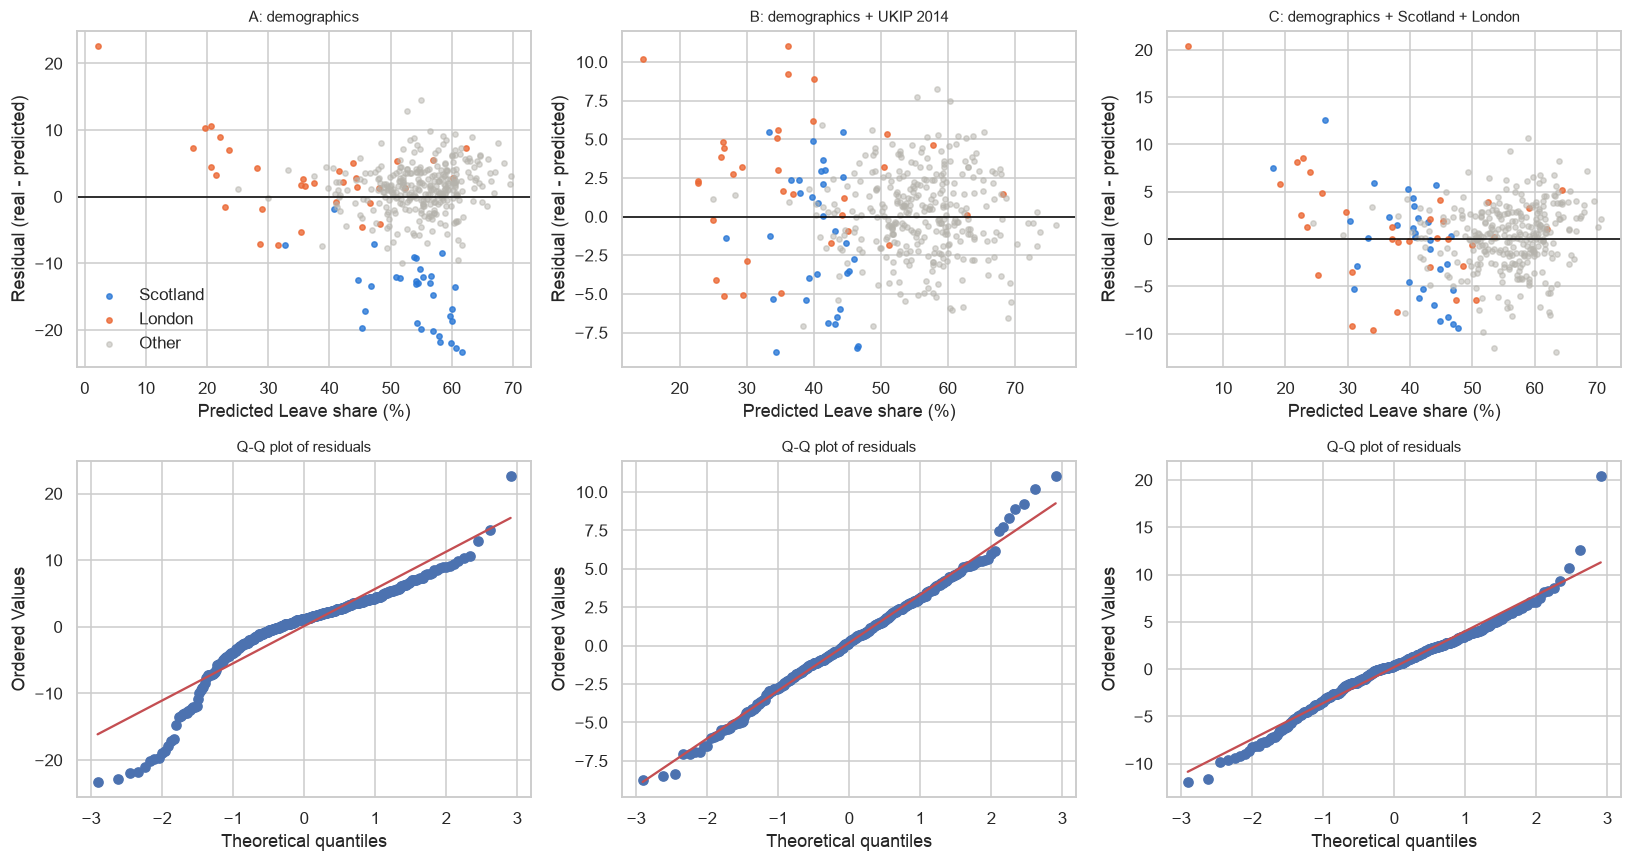

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, (name, res) in enumerate(results.items()):
    groups_ = areas.loc[res["resid"].index, "group"]
    # Top row: residual vs fitted, coloured by group
    for g, colour in COLOURS.items():
        mask = groups_ == g
        axes[0, col].scatter(res["fitted"][mask], res["resid"][mask], s=12, color=colour,
                             alpha=0.8 if g != "Other" else 0.5, label=g)
    axes[0, col].axhline(0, color="black", linewidth=1)
    axes[0, col].set_title(name, fontsize=10)
    axes[0, col].set_xlabel("Predicted Leave share (%)")
    axes[0, col].set_ylabel("Residual (real - predicted)")
    # Bottom row: Q-Q plot of the residuals
    stats.probplot(res["resid"], dist="norm", plot=axes[1, col])
    axes[1, col].set_title("Q-Q plot of residuals", fontsize=10)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()

**What we see**

- **Model A:** the residuals are **strongly skewed** (-1.37), and the Q-Q plot bends sharply at the bottom left. The blue dots show why: **Scottish councils sit 10 to 23 points below zero**. The model overestimates Leave in Scotland. The non-normal errors aren't random noise; they come from one missing piece of the story.
- **Model C**, with the Scotland dummy, removes the skew (0.04). A few extreme areas remain (excess kurtosis 2.2), so Shapiro still rejects normality.
- **Model B**, with UKIP, has close-to-normal residuals (Shapiro p = 0.13).
- **Breusch-Pagan p < 0.001 in all three models:** the error size isn't even across areas. That's why we use **robust standard errors**, so the conclusions above still hold.

### 8.2 Do the predictors repeat each other? (VIF)

**VIF, in simple words:** for each predictor, we check how well the *other* predictors can predict it. If they predict it almost perfectly, it adds little new information, and its coefficient becomes unstable. VIF = 1 / (1 - R²) of that check.

We compare our model's predictors with the four education and social grade columns all used together.

In [17]:
def vif_table(data, columns):
    d = data[columns].dropna()
    out = {}
    for c in columns:
        others = d.drop(columns=c)
        Xm = np.column_stack([np.ones(len(d)), others.to_numpy()])
        pred = Xm @ np.linalg.lstsq(Xm, d[c].to_numpy(), rcond=None)[0]
        r2 = 1 - np.sum((d[c] - pred) ** 2) / np.sum((d[c] - d[c].mean()) ** 2)
        out[c] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").round(1)


print("Predictors of model B:")
display(vif_table(areas, DEMOGRAPHICS + ["ukip_2014_pct"]).to_frame())
print("All four education and social grade columns together:")
display(vif_table(areas, ["pct_degree", "pct_noqual", "pct_ab", "pct_de"]).to_frame())

Predictors of model B:


,VIF
pct_degree,2.4
pct_65plus,2.3
pct_18_29,2.4
claimant_rate,2.1
ukip_2014_pct,1.9


All four education and social grade columns together:


,VIF
pct_degree,10.2
pct_noqual,7.3
pct_ab,15.3
pct_de,6.6


**What we see:** our model's predictors all have **VIF below 2.5**, which is fine. But using all four education and social grade columns together gives **VIF 7 to 15**: social grade AB (15.3) and graduate share (10.2) carry almost the same information. **That confirms the decision to keep only one education measure.**

### 8.3 Do a few areas drive the result? (Cook's distance)

**Cook's distance** measures how much the whole model would change if we removed one area. The usual alert level is **4 / n** (about 0.011 here). Areas above it aren't errors, but we should know them and check that the conclusions don't depend on them.

In [18]:
for name in ["A: demographics", "B: demographics + UKIP 2014"]:
    res = results[name]
    e, h = res["resid"].to_numpy(), res["leverage"]
    p = len(res["table"])
    standardised = e / (e.std() * np.sqrt(1 - h))
    cooks = standardised ** 2 / p * h / (1 - h)
    top = (areas.loc[res["resid"].index, ["area", "region", "valid_votes"]]
           .assign(residual=e, cooks_d=cooks).nlargest(6, "cooks_d"))
    print(f"\n{name}: {np.sum(cooks > 4 / res['n'])} areas above 4/n = {4 / res['n']:.3f}")
    display(top.round(3))


A: demographics: 28 areas above 4/n = 0.011


,area,region,valid_votes,residual,cooks_d
355,North Lanarkshire,Scotland,154949,-23.289,0.067
357,Glasgow City,Scotland,252809,-13.411,0.043
0,Hartlepool,North East,46100,14.521,0.029
352,West Lothian,Scotland,88508,-17.955,0.028
324,Wandsworth,London,157884,7.302,0.027
344,South Lanarkshire,Scotland,162592,-20.971,0.026



B: demographics + UKIP 2014: 32 areas above 4/n = 0.011


,area,region,valid_votes,residual,cooks_d
317,Newham,London,104699,11.021,0.102
355,North Lanarkshire,Scotland,154949,-8.344,0.095
344,South Lanarkshire,Scotland,162592,-6.506,0.047
268,Liverpool,North West,203554,-7.065,0.043
357,Glasgow City,Scotland,252809,-5.413,0.035
310,Hounslow,London,115076,8.866,0.032


**What we see:** in Model A the most influential areas are **North Lanarkshire, Glasgow and West Lothian** (Scotland again), plus **Hartlepool**, which voted far more Leave (70%) than its demographics predict. In Model B, **Newham** (East London) stands out: it voted more Leave than its low 2014 UKIP vote would suggest.

**City of London** has an extreme graduate share (68%), so its prediction is extreme. But with only 4,399 votes it carries almost no weight in the weighted model.

### 8.4 Where does the model fail? (t-tests on residuals)

If the model works equally well everywhere, residuals should average **zero** in every group. A **one-sample t-test** checks whether a group's average residual is really different from zero.

Null hypothesis: "the model is right on average for this group".

In [19]:
res_a = results["A: demographics"]["resid"]
res_c = results["C: demographics + Scotland + London"]["resid"]
rows = []
for label, mask in [("England outside London", (areas["nation"] == "England") & (areas["london"] == 0)),
                    ("London", areas["london"] == 1),
                    ("Scotland", areas["scotland"] == 1),
                    ("Wales", areas["nation"] == "Wales")]:
    for model, r in [("A", res_a), ("C", res_c)]:
        x = r[mask[r.index]]
        t = stats.ttest_1samp(x, 0)
        rows.append({"group": label, "model": model, "n": len(x), "mean_residual": x.mean(),
                     "t": t.statistic, "p": t.pvalue})
display(pd.DataFrame(rows).round(3))

,group,model,n,mean_residual,t,p
0,England outside London,A,293,1.520,7.516,0.000
1,England outside London,C,293,0.485,2.538,0.012
2,London,A,33,2.809,2.786,0.009
3,London,C,33,0.939,0.921,0.364
4,Scotland,A,32,-14.610,-15.679,0.000
5,Scotland,C,32,-0.687,-0.730,0.471
6,Wales,A,22,-1.406,-2.101,0.048
7,Wales,C,22,-3.174,-5.032,0.000


**What we see**

- **Model A, Scotland:** the mean residual is about **-14.6 points** (p < 0.001). The demographics model expects much more Leave than Scotland delivered. Notebook 01 found about -17 points with a held-out test, which tells the same story.
- **Model A, London:** about +2.8 points. With the same demographics, London voted *slightly more* Leave than predicted. The famous London Remain vote is **mostly explained by its demographics**.
- **Model C:** the dummies bring Scotland and London close to zero by design. **Wales** now stands out: about **3.2 points less Leave** than predicted (p < 0.001). Once Scotland has its own term, the model learns a lower baseline for the rest of Great Britain, and Wales sits below it. Worth a mention in the presentation and the machine-learning part.

## 9. Which factors matter most?

Coefficients use different units (points of graduates, points of claimants, and so on), so we can't compare them directly. We use two measures of **importance**:

- **Standardised coefficient (beta):** the effect of a **1 standard deviation** change in the predictor, in standard deviations of Leave. All predictors are then on the same scale.
- **Unique R² (drop-one test):** we remove one predictor and refit the model. The **drop in R²** is what only that predictor explains. If it's close to 0, other variables already carry its information.

,model,variable,standardised_beta,unique_r2
0,A,pct_degree,-0.898,0.411
1,A,pct_65plus,-0.018,0.000
2,A,pct_18_29,-0.148,0.009
3,A,claimant_rate,-0.248,0.032
4,B,pct_degree,-0.470,0.076
5,B,pct_65plus,-0.125,0.006
6,B,pct_18_29,-0.109,0.005
7,B,claimant_rate,0.011,0.000
8,B,ukip_2014_pct,0.659,0.197
9,C,pct_degree,-0.876,0.327


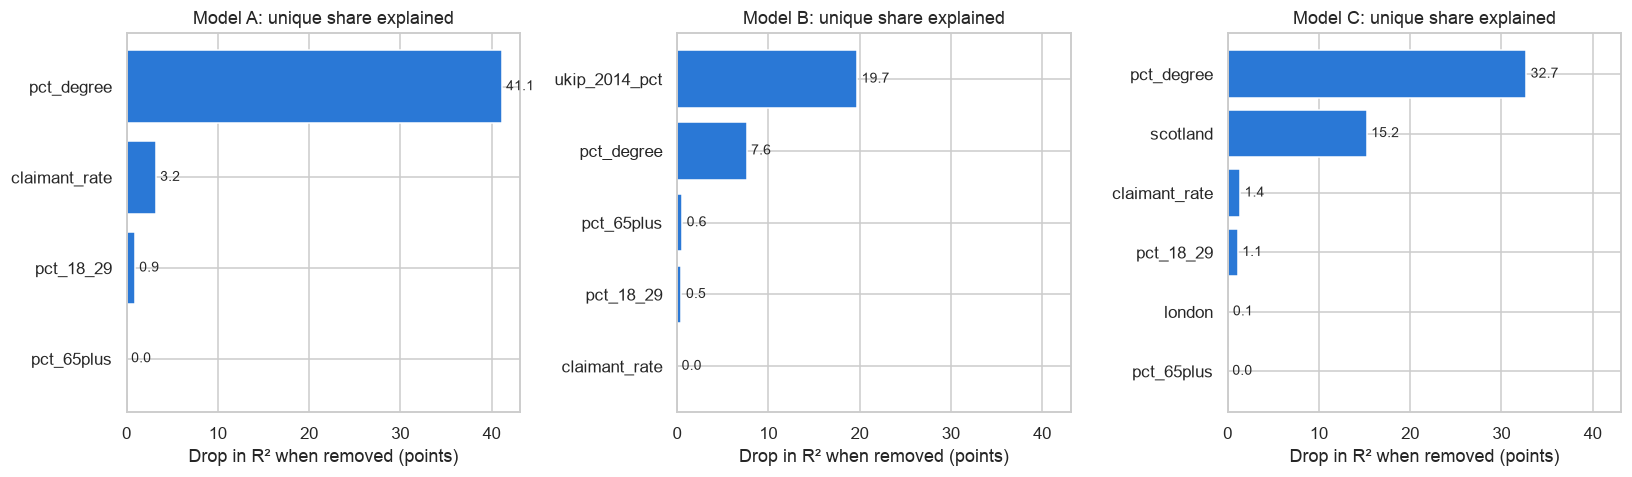

In [20]:
importance_rows = []
for name in ["A: demographics", "B: demographics + UKIP 2014", "C: demographics + Scotland + London"]:
    X, full = MODELS[name], results[name]
    sd_y = areas.loc[full["resid"].index, "leave_pct"].std()
    for var in X:
        beta_std = full["table"].loc[var, "coef"] * full["X"][var].std() / sd_y
        reduced = fit_ols(areas, "leave_pct", [v for v in X if v != var])
        importance_rows.append({"model": name[0], "variable": var, "standardised_beta": beta_std,
                                "unique_r2": full["r2"] - reduced["r2"]})
importance = pd.DataFrame(importance_rows)
display(importance.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, model in zip(axes, ["A", "B", "C"]):
    d = importance[importance["model"] == model].sort_values("unique_r2")
    ax.barh(d["variable"], 100 * d["unique_r2"], color=SCOTLAND)
    for i, v in enumerate(d["unique_r2"]):
        ax.text(100 * v + 0.5, i, f"{100 * v:.1f}", va="center", fontsize=9)
    ax.set_title(f"Model {model}: unique share explained")
    ax.set_xlabel("Drop in R² when removed (points)")
fig.tight_layout()
plt.show()

**What we see**

- **Model A:** **graduate share alone uniquely explains 41 of the 72 points of R²**, with a standardised beta of -0.90. Age 65+ adds **nothing** once education is known. Claimant rate adds 3 points, and 18-29 adds 1.
- **Model B:** UKIP 2014 takes over (20 points unique), but graduate share **still adds 8 points on its own**. Education matters even beyond earlier political mood.
- **Model C:** after education (33 points), **being in Scotland is the second most important factor (15 points)**. London adds nothing.

**KPI to remember:** *education is the main demographic driver of the Leave vote, and Scotland is the main exception that demographics can't explain.*

## 10. Do neighbouring areas vote alike? (spatial autocorrelation)

**Why it matters:** most tests assume each area is an **independent** observation. But neighbouring areas share local media, economy and history. If neighbours vote alike, we effectively have fewer independent observations than 380, and our p-values look stronger than they really are.

**Moran's I, in simple words:** for each area, we compare its value with the average of its **6 nearest neighbours**.
- I near **0**: neighbours are no more alike than random areas.
- I near **1**: strong clustering (high values next to high values).

**Permutation test:** we shuffle the values randomly across the map 9,999 times and compute Moran's I each time. The p-value is the share of shuffles that cluster as strongly as the real map.

We test it on **Leave share** and on the **residuals** of models A and C. Clustered residuals mean the model misses something regional.

In [21]:
# 1. Centre point of each area (centroid of its largest polygon)
def centroid(geometry):
    polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    best_area, cx, cy = 0, 0, 0
    for polygon in polygons:
        ring = np.asarray(polygon[0])
        x, y = ring[:, 0], ring[:, 1]
        cross = x[:-1] * y[1:] - x[1:] * y[:-1]
        a = cross.sum() / 2
        if abs(a) > best_area:
            best_area = abs(a)
            cx = ((x[:-1] + x[1:]) * cross).sum() / (6 * a)
            cy = ((y[:-1] + y[1:]) * cross).sum() / (6 * a)
    return cx, cy


centres = {f["properties"]["code"]: centroid(f["geometry"]) for f in geo["features"]}
xy = np.array([centres[c] for c in areas["code"]])
xy[:, 0] *= np.cos(np.radians(54))   # degrees of longitude are shorter in the UK

# 2. Weight matrix: each area's 6 nearest neighbours, weight 1/6 each
distance = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(axis=-1))
np.fill_diagonal(distance, np.inf)
nearest = np.argsort(distance, axis=1)[:, :6]
W = np.zeros_like(distance)
W[np.repeat(np.arange(len(W)), 6), nearest.ravel()] = 1 / 6


def morans_i(values):
    z = values - values.mean()
    return len(z) / W.sum() * (z @ W @ z) / (z @ z)


def moran_test(values, n_perm=9999):
    observed = morans_i(values)
    shuffled = np.array([morans_i(rng.permutation(values)) for _ in range(n_perm)])
    p = (np.sum(shuffled >= observed) + 1) / (n_perm + 1)
    return observed, p


expected = -1 / (len(areas) - 1)
for label, values in [("Leave share", areas["leave_pct"]),
                      ("Residuals, model A", results["A: demographics"]["resid"].reindex(areas.index)),
                      ("Residuals, model C", results["C: demographics + Scotland + London"]["resid"].reindex(areas.index))]:
    I, p = moran_test(values.to_numpy())
    print(f"{label:20s} Moran's I = {I:.3f}  (no clustering would give {expected:.3f}),  p = {p:.4f}")

Leave share          Moran's I = 0.660  (no clustering would give -0.003),  p = 0.0001
Residuals, model A   Moran's I = 0.748  (no clustering would give -0.003),  p = 0.0001
Residuals, model C   Moran's I = 0.417  (no clustering would give -0.003),  p = 0.0001


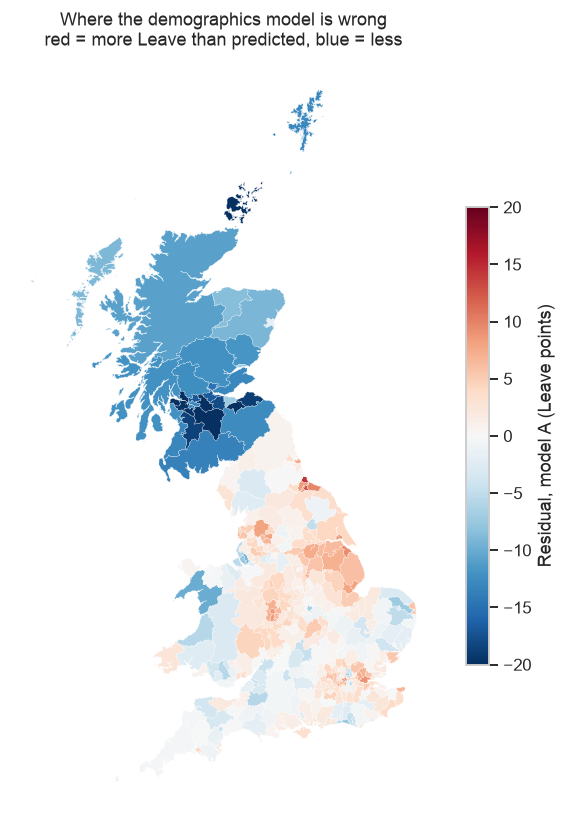

In [22]:
# Map of model A residuals: red = more Leave than predicted, blue = less
res_map = results["A: demographics"]["resid"].reindex(areas.index)
lookup = dict(zip(areas["code"], res_map))
polys, vals = [], []
for f in geo["features"]:
    g = f["geometry"]
    for polygon in (g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]):
        polys.append(np.asarray(polygon[0]))
        vals.append(lookup[f["properties"]["code"]])

fig, ax = plt.subplots(figsize=(7, 9))
collection = PolyCollection(polys, array=np.array(vals), cmap="RdBu_r", edgecolor="white", linewidth=0.15)
collection.set_clim(-20, 20)
ax.add_collection(collection)
ax.autoscale()
ax.set_aspect(1 / np.cos(np.radians(54)))
ax.axis("off")
fig.colorbar(collection, ax=ax, shrink=0.6, label="Residual, model A (Leave points)")
ax.set_title("Where the demographics model is wrong\nred = more Leave than predicted, blue = less")
plt.show()

**What we see**

- **Leave share: Moran's I = 0.66** (p < 0.001). Neighbouring areas vote very alike.
- **Model A residuals: I = 0.75.** The model's errors cluster *even more* than the vote itself. The map shows a solid blue block over **Scotland**, darkest in the Central Belt around Glasgow and Lanarkshire: the model is wrong in the same direction across a whole nation. Red patches (more Leave than predicted) appear in eastern England, Lincolnshire and the North East coast.
- **Model C residuals: I = 0.42.** Clustering drops by almost half once Scotland and London have their own terms, but it doesn't disappear (p < 0.001). Smaller regional patterns remain, such as eastern England and Wales.

**What this means for the project**

1. The 380 areas aren't fully independent, so p-values from ordinary tests are **too optimistic**. We present effect sizes and confidence intervals rather than tiny p-values.
2. It supports the **held-out-region test** from notebook 01: it checks whether the model works in a region it has never seen, which is a fairer test when neighbours are alike.
3. For a more advanced model, you could add region effects or a spatial lag. That's optional for the MVP.

## 11. Scotland: is Remain 2016 linked to Yes 2014?

With only **32 councils**, normal-theory tests are fragile. We use three tools that don't rely on the bell curve:

1. **Permutation test:** shuffle the Yes values across councils 9,999 times. How often does a correlation as strong as the real one appear by chance?
2. **Bootstrap confidence interval** (`stats.bootstrap`): resample the 32 councils with replacement 9,999 times and recompute Spearman each time. The middle 95% of the results is the interval.
3. **Fisher confidence interval** for Pearson r (from `pearsonr`).

Then a **power calculation**: how strong would a correlation need to be for 32 councils to detect it reliably?

In [23]:
def permutation_p(x, y, n_perm=9999):
    observed = np.corrcoef(x, y)[0, 1]
    shuffled = np.array([np.corrcoef(x, rng.permutation(y))[0, 1] for _ in range(n_perm)])
    return (np.sum(np.abs(shuffled) >= abs(observed)) + 1) / (n_perm + 1)


def spearman_stat(x, y):
    return stats.spearmanr(x, y).statistic


PAIRS = [("remain_pct", "yes_pct"), ("yes_pct", "claimant_rate"), ("yes_pct", "child_poverty_pct"),
         ("yes_pct", "pct_de"), ("yes_pct", "pct_degree"), ("remain_pct", "pct_degree"), ("remain_pct", "pct_65plus")]

rows = []
for a, b in PAIRS:
    x, y = scotland[a].to_numpy(), scotland[b].to_numpy()
    pearson = stats.pearsonr(x, y)
    ci = pearson.confidence_interval()
    boot = stats.bootstrap((x, y), spearman_stat, paired=True, vectorized=False,
                           n_resamples=9999, random_state=rng, method="percentile")
    rows.append({"pair": f"{a} vs {b}", "pearson_r": pearson.statistic,
                 "pearson_95ci": f"[{ci.low:.2f}, {ci.high:.2f}]", "permutation_p": permutation_p(x, y),
                 "spearman": spearman_stat(x, y),
                 "spearman_bootstrap_95ci": f"[{boot.confidence_interval.low:.2f}, {boot.confidence_interval.high:.2f}]"})
display(pd.DataFrame(rows).round(3))

# Power: smallest correlation 32 councils detect 80% of the time (alpha = 0.05)
n_councils = len(scotland)
z_needed = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) / np.sqrt(n_councils - 3)
print(f"With {n_councils} councils, a correlation is detected reliably (80% power) only if |r| >= {np.tanh(z_needed):.2f}")

,pair,pearson_r,pearson_95ci,permutation_p,spearman,spearman_bootstrap_95ci
0,remain_pct vs yes_pct,-0.096,"[-0.43, 0.26]",0.603,-0.039,"[-0.41, 0.34]"
1,yes_pct vs claimant_rate,0.848,"[0.71, 0.92]",0.000,0.860,"[0.68, 0.94]"
2,yes_pct vs child_poverty_pct,0.783,"[0.60, 0.89]",0.000,0.790,"[0.55, 0.91]"
3,yes_pct vs pct_de,0.667,"[0.41, 0.82]",0.000,0.729,"[0.45, 0.88]"
4,yes_pct vs pct_degree,-0.529,"[-0.74, -0.22]",0.002,-0.671,"[-0.83, -0.41]"
5,remain_pct vs pct_degree,0.590,"[0.30, 0.78]",0.000,0.325,"[-0.06, 0.65]"
6,remain_pct vs pct_65plus,-0.269,"[-0.57, 0.09]",0.135,-0.224,"[-0.54, 0.15]"


With 32 councils, a correlation is detected reliably (80% power) only if |r| >= 0.48


**What we see**

- **Remain 2016 vs Yes 2014: r = -0.10**, permutation p = 0.60, 95% CI **-0.43 to 0.26**. There's no detectable link: Scotland's Remain map and Yes map are different maps.
- **But be careful with the wording.** With 32 councils we can only reliably detect |r| ≥ 0.48. The interval still allows a moderate link either way. So say **"no detectable link"**, not "no link".
- **Yes 2014 follows deprivation:** claimant rate r = 0.85 (CI 0.71 to 0.92), child poverty 0.78, social grade DE 0.67. All are solid, and permutation and bootstrap agree.
- **Remain vs graduate share:** Pearson says 0.59, but Spearman only 0.33, with a bootstrap interval **including 0** (-0.06 to 0.65). A few very educated councils (Edinburgh, East Renfrewshire, East Dunbartonshire) drive it. **Don't present it as a strong finding.**

## 12. *(Optional)* Twitter: did the Brexit debate shift before the vote?

**This section is optional.** Tweets have no local geography, so they can't be part of the area analysis. If a Twitter part stays in the project, it covers only **Brexit tweets around the vote**, to describe how the online debate moved. There is no disinformation analysis.

We use only tweets from **before 06:00 UTC on 23 June** (`pre_vote`), and we skip the missing hour. The measure is the **Leave share of tweets that took a side** (Leave / (Leave + Remain)).

**The tests**

1. **Kendall's τ (tau) trend test:** a rank test of "does the share go steadily up or down over time?". It doesn't need normal data.
2. **Lag-1 autocorrelation:** is each day similar to the day before? If so, days aren't independent, and the trend p-value is too optimistic.
3. **Chi-square test + Cramér's V:** compares the stance mix (Leave, Remain, Neutral) in the **first** and **last** pre-vote weeks. With hundreds of thousands of tweets, chi-square is always significant, so **Cramér's V** (0 = no difference, 1 = complete difference) tells us whether the change is big. Rough guide: 0.1 small, 0.3 medium, 0.5 large.

**Reminder:** stance labels come from a classifier (59.5% accuracy) and Twitter users aren't voters. These tests describe the **debate**, not public opinion, and say nothing about whether tweets were true.

In [24]:
pre = hourly[(hourly["period"] == "pre_vote") & (~hourly["file_missing"])].copy()
pre["date"] = pre["hour_utc"].dt.date
daily = pre.groupby("date")[["leave", "remain", "neutral"]].sum()
daily["leave_share"] = daily["leave"] / (daily["leave"] + daily["remain"])
daily["day"] = np.arange(len(daily))

# 1. Trend test
tau = stats.kendalltau(daily["day"], daily["leave_share"])
print(f"Kendall trend test: tau = {tau.statistic:.2f}, p = {tau.pvalue:.1e}")

# 2. Is each day like the day before?
lag1 = daily["leave_share"].autocorr(lag=1)
print(f"Lag-1 autocorrelation: {lag1:.2f}")

# 3. First vs last week: stance mix
first = daily.iloc[:7][["leave", "remain", "neutral"]].sum()
last = daily.iloc[-7:][["leave", "remain", "neutral"]].sum()
table = np.array([first, last])
chi2, p, dof, _ = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.sum() * (min(table.shape) - 1)))
print(f"Chi-square = {chi2:,.0f}, p = {p:.1e}, Cramér's V = {cramers_v:.3f}")
display(pd.DataFrame({"first week": first / first.sum(), "last week": last / last.sum()}).round(3))

Kendall trend test: tau = -0.47, p = 9.6e-06
Lag-1 autocorrelation: 0.60
Chi-square = 5,671, p = 0.0e+00, Cramér's V = 0.063


,first week,last week
leave,0.474,0.399
remain,0.186,0.236
neutral,0.340,0.365


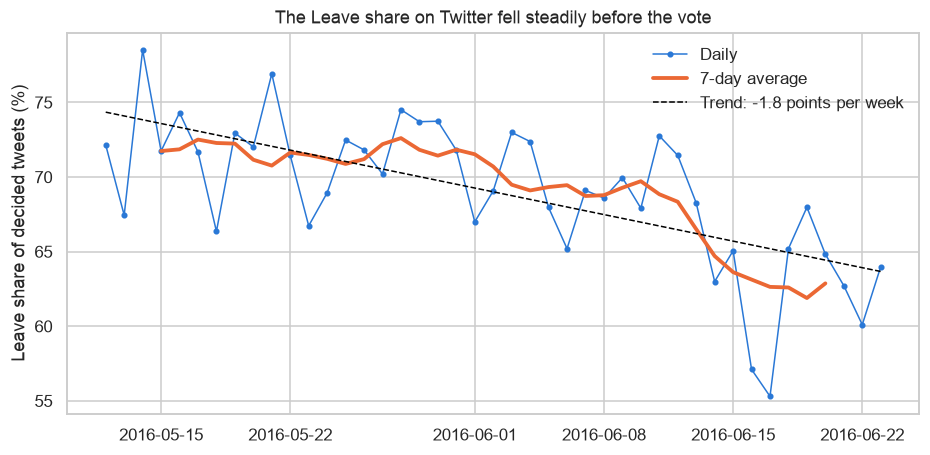

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.5))
dates = pd.to_datetime(daily.index)
ax.plot(dates, 100 * daily["leave_share"], color=SCOTLAND, marker="o", markersize=3, linewidth=1, label="Daily")
ax.plot(dates, 100 * daily["leave_share"].rolling(7, center=True).mean(), color=LONDON, linewidth=2.5,
        label="7-day average")
slope, intercept = np.polyfit(daily["day"], 100 * daily["leave_share"], 1)
ax.plot(dates, intercept + slope * daily["day"], color="black", linestyle="--", linewidth=1,
        label=f"Trend: {7 * slope:+.1f} points per week")
ax.set_ylabel("Leave share of decided tweets (%)")
ax.set_title("The Leave share on Twitter fell steadily before the vote")
ax.legend(frameon=False)
plt.show()

**What we see**

- **Kendall's τ = -0.47** (p < 0.001): the Leave share among decided tweets **fell steadily** before the vote.
- **Lag-1 autocorrelation is about 0.6:** each day looks like the day before, so the 43 days aren't 43 independent observations. The trend is real, but the exact p-value is too optimistic.
- **Chi-square** is huge and p is essentially 0, **but Cramér's V is only about 0.06, a small effect**. Leave fell from about 47% to 40% of all tweets, and Remain rose from about 19% to 24%. That's a visible shift in the debate, but a modest one.
- **Lesson:** with big data, report **effect sizes and shares**, not p-values.

## 13. Export results for the Tableau dashboards

The Tableau dashboards are the next step of the project. This section saves two files that Tableau can read directly.

**File 1: `tableau_model_results.csv`, one row per area.** For each area it holds:
- the real Leave share;
- the **prediction** of each of the three models (A: demographics, B: + UKIP 2014, C: + Scotland and London terms);
- the **residual** of each model: real minus predicted. Negative = the area voted Leave **less** than the model expected; positive = **more**;
- the area's **graduate quintile** (1 = the fifth of areas with the fewest graduates, 5 = the most), for the KPI charts.

With it, Tableau can draw a **"predicted vs actual" map**, and a **map of the model's errors** like the one in section 10, where Scotland stands out.

**File 2: `tableau_kpis.csv`, one row per characteristic.** The KPI table from section 6: the Leave share in the bottom and top fifth of areas, the gap between them, and the share each characteristic explains alone (R²). It feeds a KPI bar chart like the one in section 6.

**How to use them in Tableau:** open `gb_areas_boundaries.geojson` as a **Spatial file**, add `tableau_model_results.csv` as a **Text file**, and join them on `code`. `tableau_kpis.csv` doesn't need the map: open it on its own.

In [26]:
# File 1: one row per area, with each model's prediction and residual
model_results = areas[["code", "area", "region", "nation", "leave_pct", "pct_degree", "valid_votes"]].copy()
for short, name in [("A", "A: demographics"), ("B", "B: demographics + UKIP 2014"),
                    ("C", "C: demographics + Scotland + London")]:
    model_results[f"predicted_{short}"] = results[name]["fitted"].reindex(areas.index)
    model_results[f"residual_{short}"] = results[name]["resid"].reindex(areas.index)

# Graduate quintile: 1 = the fifth of areas with the fewest graduates, 5 = the most
model_results["graduate_quintile"] = pd.qcut(model_results["pct_degree"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

model_results = model_results.round(2)
model_results.to_csv(DATA_DIR / "tableau_model_results.csv", index=False)
print("Saved tableau_model_results.csv:", model_results.shape)

# Check: model A's average error in Scotland (should match section 8.4)
print("Model A mean residual in Scotland:", round(model_results.loc[model_results["nation"] == "Scotland", "residual_A"].mean(), 1))

# File 2: the KPI table from section 6
kpis.round(2).to_csv(DATA_DIR / "tableau_kpis.csv", index=False)
print("Saved tableau_kpis.csv:", kpis.shape)

display(model_results.head())

Saved tableau_model_results.csv: (380, 14)
Model A mean residual in Scotland: -14.6
Saved tableau_kpis.csv: (10, 5)


,code,area,region,nation,leave_pct,pct_degree,valid_votes,predicted_A,residual_A,predicted_B,residual_B,predicted_C,residual_C,graduate_quintile
0,E06000001,Hartlepool,North East,England,69.57,17.60,46100,55.05,14.52,66.65,2.92,58.89,10.68,1
1,E06000002,Middlesbrough,North East,England,65.48,18.54,61358,52.65,12.83,63.93,1.55,56.13,9.35,1
2,E06000003,Redcar and Cleveland,North East,England,66.19,18.93,72714,56.37,9.82,63.01,3.18,59.68,6.51,1
3,E06000004,Stockton-on-Tees,North East,England,61.73,22.82,100415,53.24,8.49,59.05,2.68,55.46,6.27,2
4,E06000005,Darlington,North East,England,56.18,23.72,55166,52.70,3.49,56.53,-0.35,55.23,0.95,2


**What we see:** 380 rows with the three predictions and residuals for every area, and a 10-row KPI table. The check confirms that model A's average error in Scotland is about -14.6 points, as in section 8.4: that's what the error map in Tableau should show.

## 14. Summary of all tests

| Step | Test | Result | Conclusion |
|---|---|---|---|
| 3 | Skewness, Shapiro-Wilk | Leave skew -0.67; graduates 1.2, 18-29 1.5, non-UK-born 2.0 | Use robust methods; Spearman next to Pearson |
| 4 | Pearson, Spearman + BH | Graduates r = -0.77; UKIP 0.87; child poverty not significant | Education is the strongest demographic link |
| 4 | Pearson vs Spearman gap | 18-29: -0.37 vs -0.12 | The age-18-29 link is driven by a few areas |
| 5 | Levene | p < 0.001 | Unequal spread, so Welch, not classic ANOVA |
| 5 | Welch ANOVA, Kruskal-Wallis | η² = 0.44, ε² = 0.36 | Regions differ a lot |
| 6 | Quintile KPIs | Graduates -24.1 pts, UKIP +24.5, pay -15.1, claimant +1.2 | Education gap large, unemployment gap ~0 |
| 7 | Weighted OLS, HC3 | Model A R² 0.72; B 0.91; C 0.88; Scotland -15.5 pts | Scotland isn't explained by demographics |
| 8 | Breusch-Pagan | p < 0.001 in all models | Robust standard errors needed |
| 8 | VIF | Model < 2.5; education + class together 7-15 | Keep one education measure |
| 8 | t-tests on residuals | Scotland -14.6, London +2.8 (model A); Wales -3.2 (model C) | London explained by demographics, Scotland not |
| 9 | Unique R² | Graduates 41 pts (A); Scotland 15 pts (C) | Education first, Scotland second |
| 10 | Moran's I | Leave 0.66; residuals A 0.75, C 0.42 | Areas aren't independent; use held-out regions |
| 11 | Permutation, bootstrap | Remain vs Yes r = -0.10, CI -0.43 to 0.26; power only for \|r\| ≥ 0.48 | "No detectable link" |
| 12 (optional) | Kendall, chi-square, Cramér's V | τ = -0.47; V ≈ 0.06 | Leave's Twitter lead narrowed, a small effect |

## Decisions for the next steps

- **Tableau:** build the dashboards from the files exported in section 13: the Leave map, the KPI chart, and the predicted vs actual and error maps.
- **Machine learning:** use **one education measure** (graduate share), plus age and claimant rate.
- Report the model **with and without UKIP 2014**: one explains, the other predicts.
- Use **robust standard errors** and present **confidence intervals**.
- Keep the **held-out-region test**, because neighbouring areas aren't independent.
- Make Scotland the centre of the "where the explanation breaks" story: demographics overestimate Leave there by about 15 points.

## 15. The whole notebook in simple words

This notebook checks whether the patterns from notebook 01 are **real**, **how big** they are, and **where they stop working**.

1. **Shape of the data:** most variables aren't perfect bell curves. Several have a few extreme areas (London, student towns). So we use tests that cope with that: Spearman, Welch, robust errors, permutation and bootstrap.
2. **Correlations:** the fewer graduates an area has, the more it voted Leave (r = -0.77). This holds even with ranks instead of values. Unemployment and child poverty show almost no link.
3. **Regions:** they really differ, and region alone explains 44% of the differences between areas.
4. **KPIs:** the fifth of areas with the fewest graduates voted **63% Leave**, the fifth with the most voted **39%**, a **24-point gap**. The pay gap is 15 points, and the unemployment gap is about 1.
5. **Regression:** combining factors, education is by far the most important. Age adds little once we know education. Even with the same demographics, **Scotland voted about 15 points less Leave**. London doesn't need its own explanation: its demographics explain it.
6. **Checks:** the model's errors are uneven and cluster on the map, mostly in Scotland. We use robust methods and test the model on regions it hasn't seen.
7. **Scotland:** Remain in 2016 isn't linked to Yes in 2014, but with 32 councils we can only say the link isn't detectable. Yes follows deprivation closely.
8. *(Optional)* **Twitter:** Leave's share of Brexit tweets fell steadily before the vote, but the change is small, and tweets aren't votes.
9. **Tableau export:** we save the models' predictions and errors for every area, and the KPI table, ready for the dashboards.

**Next:** notebook 03 (Scotland in depth), the Tableau dashboards, then the machine-learning model.